In [1]:
import xarray as xr
import matplotlib.pyplot as plt 
import cartopy.crs as ccrs
import geopandas as gpd
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, Normalize
import cmcrameri.cm as cmc
import seaborn as sns
from tqdm.notebook import tqdm

# Helpers

In [2]:
plt.style.use('robin')
proj = ccrs.NorthPolarStereo(0,70)

def sigmoid(x):
    return 1/(1+np.exp(-x))
def logit(x):
    return np.log(x/(1-x)) 

inch_to_cm = 2.54

ds_regions = xr.open_dataarray('/Data/skd/projects/global/cmip6_precursors/aux/ERA5_rainfall_regions.nc')
ds_regions = ds_regions.where(ds_regions==14, drop=True).sel(lon=slice(0,None))


In [3]:
def add_grid_coastlines(ax, coastline_color='.4', grid_color = '.7'):
    ax.coastlines(color=coastline_color, lw=.5)
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,       # add tick labels
        linewidth=0.4,
        linestyle="-",
        alpha=0.5,
        zorder=2,
        color=grid_color
    )

# Load data

In [4]:
ds_features = xr.open_zarr("/Data/gfi/users/rogui7909/data/ERA5/dynamical_variables/dl_inputs_day_100km_1940-2024_NPS_v2.zarr").load()

run_id ='h82d4u1m'
ds_predictions = xr.open_dataset(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_model_skill.nc').sortby('time')
ds_attrs = xr.open_dataset(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_ALL_attributions_v3_lrpzplus.nc').transpose('y','x',...)
lrp_normed = ds_attrs.attributions_lrp.sum('var_name')/ds_attrs.attributions_lrp.sum('var_name').clip(0).sum(['x','y'])
lrp_normed_vars = ds_attrs.attributions_lrp/ds_attrs.attributions_lrp.sum('var_name').clip(0).sum(['x','y'])
ds_attrs['lrp_normed'] = lrp_normed

gdf_cyclones = gpd.read_file(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_cyclones_data_revised_segmentation_thresh0.001_buffer500_v2_zplus_rolling1.geojson')

gdf_cyclones = gdf_cyclones.set_crs(proj, allow_override=True)
all_cyclones = gpd.read_file('/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/all_cyclones.geojson')
all_cyclones = all_cyclones.set_crs(proj, allow_override=True)



# Figures
## Figure 1: example of input maps

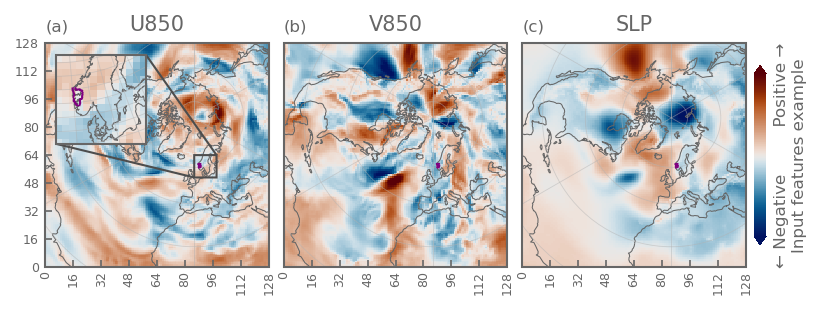

In [5]:
data=((ds_features[['u850','v850','msl']].sel(time='2016-08-05').to_array('var_name')-ds_features.data_mean)/ds_features.data_std)
plot = data.plot(col='var_name',  
                 transform=proj,
                 subplot_kws=dict(projection=proj), vmax=3,
                 aspect=.8, size=2, rasterized=True, 
                 cbar_kwargs=dict(extend='both', shrink=.7, pad=.01, aspect=15),
                 cmap = cmc.vik)
for k,ax in enumerate(plot.axs.flatten()):
    add_grid_coastlines(ax)
    ax.set_extent([-1e7,5e6, -1e7, 5e6], crs=proj)
    ax.set_title(f'Prediction at D{-6+k}', size=8)
    ds_regions.fillna(0).plot.contourf(colors='C4', levels=[13,15], add_colorbar=False,ax=ax, transform=ccrs.PlateCarree())
    ds_regions.fillna(0).plot.contour(colors='purple', levels=[13], 
                                 add_colorbar=False,
                                 ax=ax, 
                                 transform=ccrs.PlateCarree(), 
                                 zorder=200,
                                 linewidths=1)
    if k ==0:
        axins = ax.inset_axes(
            [0.05, 0.55, 0.4, 0.4],
            projection=proj,
            zorder=100)
        data.isel(var_name=k).plot(ax=axins, add_colorbar=False, cmap=cmc.vik_r, vmax=3, rasterized=True)
        axins.set(xlim=(0, 1.5e6), ylim=(-4e6, -2.5e6), xticklabels=[], yticklabels=[])
        add_grid_coastlines(axins)
        ax.indicate_inset_zoom(axins, edgecolor=".3", linewidth=1, alpha=1)
        ds_regions.fillna(0).plot.contour(colors='purple', levels=[13], 
                                 ax=axins, 
                                 transform=ccrs.PlateCarree(), 
                                 zorder=200,
                                 linewidths=1)
        axins.set_title('')
    
    ax.set_xticks(np.linspace(-1e7, 5e6, 9))
    ax.set_xticklabels(np.arange(0, 129, 16), rotation=90, size=6,)
    ax.xaxis.set_tick_params(pad=2)
    ax.set_xlabel('')

ax=plot.axs.flat[0]
ax.set_yticks(np.linspace(-1e7, 5e6, 9))
ax.set_yticklabels(np.arange(0, 129, 16), size=6,)
ax.yaxis.set_tick_params(pad=3)
ax.set_ylabel('')
plot.axs.flat[0].set_title('U850')
plot.axs.flat[1].set_title('V850')
plot.axs.flat[2].set_title('SLP')
plot.cbar.ax.set_yticks([])
plot.cbar.ax.set_ylabel('← Negative         Positive →\nInput features example') 

plot.axs.flat[0].text(0,1.04,'(a)', transform=plot.axs.flat[0].transAxes, va='bottom', ha='left', weight='normal')
plot.axs.flat[1].text(0,1.04,'(b)', transform=plot.axs.flat[1].transAxes, va='bottom', ha='left', weight='normal')
plot.axs.flat[2].text(0,1.04,'(c)', transform=plot.axs.flat[2].transAxes, va='bottom', ha='left', weight='normal')


for mappable in [plot]:
    if hasattr(mappable, 'colorbar') and mappable.colorbar:
        mappable.colorbar.outline.set_visible(False)
cax = mappable.cbar.ax.tick_params
for spine in plot.cbar.ax.spines.values():
    spine.set_visible(False)

plt.savefig('../paper/plots/pdf_revisions/fig01.pdf', bbox_inches='tight')

# plt.savefig('../paper/plots/svg/fig01.svg', bbox_inches='tight')



## Figure 3: example of relevance maps

In [6]:
def find_top_cyc(df):
    return df.iloc[df.patch_attributions.argmax()]

top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(
    find_top_cyc
)

/tmp/ipykernel_2581019/227351796.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(


/tmp/ipykernel_2581019/4150779880.py:36: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
/tmp/ipykernel_2581019/4150779880.py:36: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder

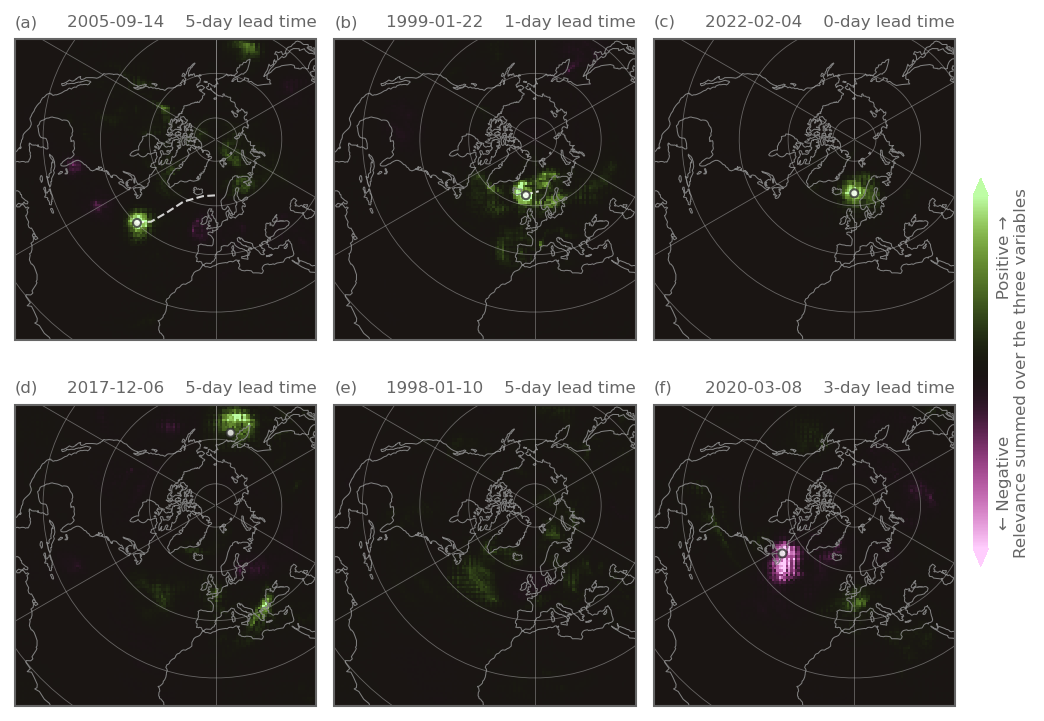

In [7]:
fig, axs = plt.subplot_mosaic("""
                              ABC.
                              ABCc
                              ABCc
                              DEFc
                              DEFc
                              DEF.
                              """,
                              figsize=(7,5), 
                            per_subplot_kw={
                                'A': dict(projection=proj),
                                'B': dict(projection=proj),
                                'C': dict(projection=proj),
                                'D': dict(projection=proj),
                                'E': dict(projection=proj),
                                'F': dict(projection=proj),
                                'c': {}  
                            },
                                  gridspec_kw=dict(
                                width_ratios=[1, 1,1, 0.05],
                                  )
                              )
                              


map_axs = np.array([[axs['A'], axs['B'], axs['C']], [axs['D'], axs['E'], axs['F']]])
for k,ax in enumerate(map_axs.flat):
    add_grid_coastlines(ax, coastline_color='.5')
    ax.set_title('')
    ax.set_title('('+chr(ord('a') + k)+')', size=8, loc='left', weight='normal')
time_of_event_list = ['2005-09-14', '1999-01-22', '2022-02-04']
timestep_past_list = [-5, -1, 0]
vmax_list = [0.003,  0.003, 0.008]
for k in range(3):
    ds_attrs.sel(time_of_event = time_of_event_list[k], timestep_past = timestep_past_list[k]).lrp_normed.plot(ax=map_axs[0,k], cmap=cmc.vanimo, transform=proj, rasterized=True, vmax=vmax_list[k], cbar_ax=axs['c'], cbar_kwargs=dict(extend='both', shrink=.5, pad=.01, aspect=10))
    df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
    cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    track_id = cyc.cyclone_track_id.values[0]
    cyc_traj = all_cyclones.query("track_id==@track_id").set_index('date').loc[:time_of_event_list[k]][timestep_past_list[k]-1:]
    map_axs[0,k].plot(cyc_traj.x, cyc_traj.y,  zorder=200, transform=proj, alpha=.8, color='1', lw=1,ls='--')
    cyc.buffer(200000).plot(ax=map_axs[0,k], edgecolor='.2', color='1', alpha=.8, zorder=300, transform=proj, )
    map_axs[0,k].set_title(f"", size=8, loc='center', weight='normal')
    map_axs[0,k].set_title(time_of_event_list[k]+'    ' +f"{-timestep_past_list[k]}-day lead time", size=8, loc='right', weight='normal')


# 2017-12-06 -5 # pacific
# 1998-01-10 -5 # weak overall
# 2020-03-08 -3 # negative cyclones
# 2015-02-19 -3 # biggest not a cyclone

time_of_event_list_fail = ['2017-12-06','1998-01-10','2020-03-08']
timestep_past_list_fail = [-5, -5, -3, -3]
vmax_list_fail = [0.003, 0.003, 0.006, 0.008]


for k in range(3):
    ds_attrs.sel(time_of_event = time_of_event_list_fail[k], timestep_past = timestep_past_list_fail[k]).lrp_normed.plot(ax=map_axs[1,k], cmap=cmc.vanimo, transform=proj, add_colorbar=False, rasterized=True, vmax=vmax_list_fail[k])
    
    if k in [0]:
        df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list_fail[k]}' & timestep_past=={timestep_past_list_fail[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
        cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    elif k in [2]:
        df_extract =gdf_cyclones.query("time_of_event=='2020-03-08' & timestep_past==-3").sort_values('patch_attributions').iloc[[0]]
        cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    if k in [0,2]:
        cyc.buffer(200000).plot(ax=map_axs[1,k], edgecolor='.2', color='1', alpha=.8, zorder=300, transform=proj, )

    map_axs[1,k].set_title(f"", size=8, loc='center', weight='normal')
    map_axs[1,k].set_title(time_of_event_list_fail[k]+'    ' +f"{-timestep_past_list_fail[k]}-day lead time", size=8, loc='right', weight='normal')


for spine in axs['c'].spines.values():
    spine.set_visible(False)
axs['c'].tick_params(left=False, right=False, labelleft=False, labelright=False, labelbottom=False, labeltop=False)
axs['c'].set_ylabel('← Negative                          Positive →\nRelevance summed over the three variables', size=8, loc='center', weight='normal')

plt.tight_layout()
plt.savefig('../paper/plots/pdf_revisions/fig03.pdf', bbox_inches='tight')


## Figure 5: neural network skill

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

climatology_freq = (ds_predictions.where(ds_predictions.dataset=='test').targets==1).sum('time')/(ds_predictions.where(ds_predictions.dataset=='test').targets>=0).sum('time')
climatology_freq = climatology_freq.isel(timestep=0).values
climatology = xr.ones_like(ds_predictions.soft_targets)*climatology_freq

persistence = ds_predictions.soft_targets.isel(timestep=0).expand_dims(timestep=ds_predictions.timestep)

prauc_clim = np.array([average_precision_score(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                        climatology.sel(timestep=k).where(ds_predictions.sel(timestep=k).dataset=='test', drop=True)) for k in range(7)])

prauc_pers = np.array([average_precision_score(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                        persistence.sel(timestep=k).where(ds_predictions.sel(timestep=k).dataset=='test', drop=True)) for k in range(7)])

prauc_nn = np.array([average_precision_score(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                        ds_predictions.sel(timestep=k).predictions.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True)) for k in range(7)])

precision, recall, _ = precision_recall_curve(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                                                persistence.sel(timestep=k).where(ds_predictions.sel(timestep=k).dataset=='test', drop=True))

/tmp/ipykernel_2581019/3837826370.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend(handlelength=2, loc='upper right')


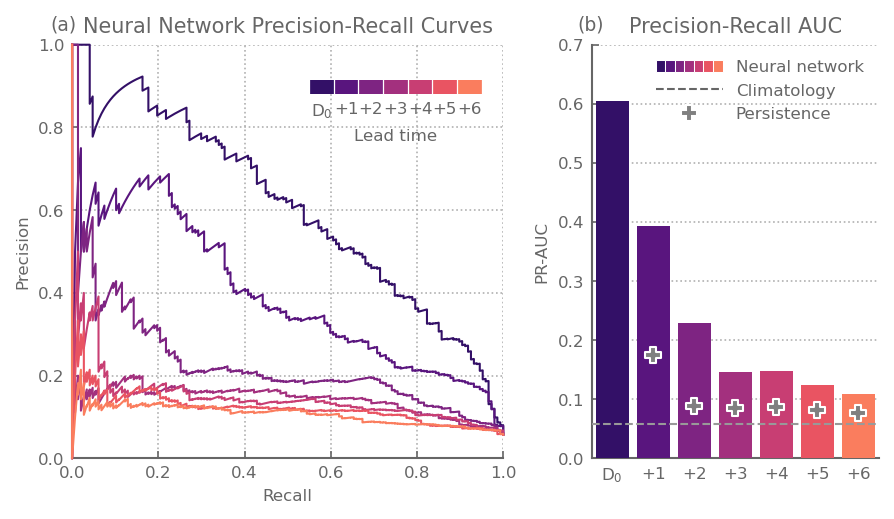

In [9]:
fig, axs = plt.subplots(1,2, figsize=(6,3.5), width_ratios=[1.5,1])

colors = sns.color_palette('magma', n_colors=10)[1:8]
for k in range(7):
    precision, recall, _ = precision_recall_curve(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                                                ds_predictions.sel(timestep=k).predictions.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True))
    axs[0].plot(recall, precision, label=None, lw=1, clip_on=False, zorder=100, color=colors[k])

list_labels =[r'D$_0\plus$'+f'{k}' if k >0 else f'D$_0$' for k in range(7)]
# for k in range(7):
#     axs[0].text(0.75, 0.90-k*0.05, list_labels[k], transform=axs[0].transAxes, color=colors[k], fontsize=8,  va='center', zorder=200, weight='bold', ha='left') 

# axs[0].axhline(climatology_freq, label='Climatology', color='.4', linestyle='--')
axs[0].set(xlim = (0,1,), ylim=(0,1))
axs[0].grid()
axs[0].legend(handlelength=2, loc='upper right')
axs[0].set_title('Neural Network Precision-Recall Curves', size=10)
axs[0].set_xlabel('Recall')
axs[0].set_ylabel('Precision')


from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

cm_lead = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 7.5), 7)
cax = axs[0].inset_axes([0.55, 0.88, 0.4, 0.035])          # x, y, width, height in axes coords
cb = plt.colorbar(ScalarMappable(norm, cm_lead), cax=cax, orientation='horizontal',
                  ticks=range(7),)

cb.outline.set_visible(False)
for s in cax.spines.values():
    s.set_visible(False)

cb.set_ticklabels(['D$_0$'] + [f'+{k}' for k in range(1, 7)])
cb.ax.tick_params(labelsize=8, length=0, bottom=False)
cb.ax.tick_params(which='minor', length=10, color='white')
cb.set_label('Lead time', fontsize=8)

# cb.dividers.set_color('white')
# cb.dividers.set_linewidth(1.5)   # adjust thickness

axs[1].bar( np.arange(0,7,1),prauc_nn ,  clip_on=False, zorder=100, color=colors, width=.8)
axs[1].scatter( np.arange(1,7,1),prauc_pers[1:] , label='Persistence predictions',  clip_on=True, zorder=100, color='.5', edgecolor='1', marker='P', s=60,)
axs[1].axhline(climatology_freq, label='Climatology', color='.6', linestyle='--', zorder=1000,)



axs[1].set_xticks(np.arange(0,7))
axs[1].set_xticklabels(['D$_0$']+[r"$\plus$"+f"{t}" for t in range(1,7)] )

nn_handle   = tuple(Patch(facecolor=c, edgecolor='white',linewidth=0.5) for c in colors)
pers_handle = Line2D([0], [0], marker='P', ls='none',
                     markerfacecolor='.5', markeredgecolor='1', markersize=np.sqrt(60))                              # or a marker, see below
clim_handle = Line2D([0], [0], color='0.4', ls='--')

axs[1].legend([nn_handle, clim_handle, pers_handle],
            ['Neural network', 'Climatology','Persistence'],
            handler_map={tuple: HandlerTuple(ndivide=None, pad=0)},
            handlelength=4, frameon=False)
axs[1].set_ylim(0,0.7)
axs[1].grid(zorder=200, axis='y')
axs[1].set_xlim(-.5,6.5)
axs[1].set_title('Precision-Recall AUC')
axs[1].set_ylabel('PR-AUC')

axs[0].text(-.05, 1.05,'(a)', transform=axs[0].transAxes, va='center', ha='left', weight='normal', size=9)
axs[1].text(-0.05, 1.05,'(b)', transform=axs[1].transAxes, va='center', ha='left', weight='normal', size=9)

plt.tight_layout()
plt.savefig('../paper/plots/pdf_revisions/fig05.pdf', bbox_inches='tight')


## Figure 6: naive averages

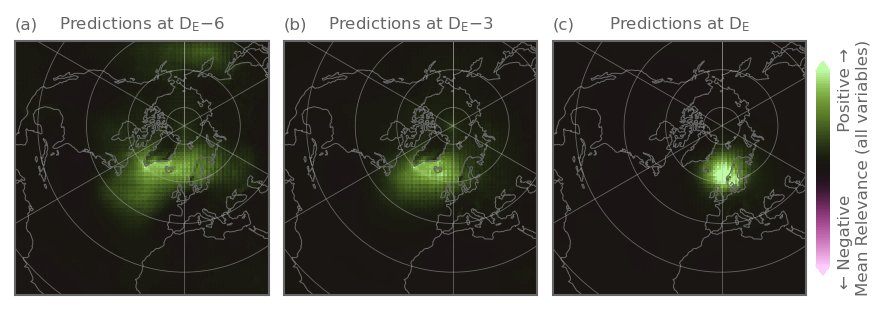

In [10]:
ds_attrs_mean = ds_attrs.lrp_normed.mean('time_of_event')

plot = (ds_attrs_mean/ds_attrs_mean.quantile(.99,['x','y'])).rolling(x=1,y=1,center=True).mean().fillna(0).sel(timestep_past=[-6,-3,0]).plot(col='timestep_past', levels=101,
                                                                                                                                                    transform=proj,
                                                                                                                                                    subplot_kws=dict(projection=proj), vmax=1.5,
                                                                                                                                                    aspect=.8, size=2.3, rasterized=True, 
                                                                                                                                                    extend='both',
                                                                                                                                                    cbar_kwargs=dict(extend='both', shrink=.7, pad=.01, aspect=15),
                                                                                                                                                    cmap = cmc.vanimo)
for k,ax in enumerate(plot.axs.flatten()):
    add_grid_coastlines(ax)
    ax.set_extent([-1e7,5e6, -1e7, 5e6], crs=proj)
    ax.tick_params(left=False, right=False, labelleft=False, labelright=False)
    ax.set_title('('+chr(ord('a') + k)+')', size=8, loc='left', weight='normal')
plot.axs[0,0].set_title(r'Predictions at D$_\text{E}\minus$6', size=8)
plot.axs[0,1].set_title(r'Predictions at D$_\text{E}\minus$3', size=8)
plot.axs[0,2].set_title(r'Predictions at D$_\text{E}$', size=8)

cax = plot.cbar.ax
for spine in cax.spines.values():
        spine.set_visible(False)

cax.tick_params(right=False, left=False, labelleft=False, labelright=False, which='both')

cax.set_ylabel('← Negative            Positive →\nMean Relevance (all variables)', size=8)

plt.savefig('../paper/plots/pdf_revisions/fig06.pdf', bbox_inches='tight')



## Figure 7: predictions are associated with cyclones

In [11]:
def find_top_cyc(df):
    return df.iloc[df.patch_attributions.argmax()]

top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(
    find_top_cyc
)

all_top_used_track = []
for time_of_event in tqdm(ds_attrs.time_of_event.values):
    all_used_cyclones = gdf_cyclones.query("is_cyclone or patch_attributions>.1").query("time_of_event==@time_of_event").set_index('timestep_past')#.cyclone_track_id.dropna()
    used_cyclones_at_D0 = all_used_cyclones.loc[[0]].sort_values("patch_attributions", ascending=False)#.cyclone_track_id.dropna().values

    df_default =     df_out = pd.DataFrame({
        'time_of_event': time_of_event,
        'main_cyclone_D0_exists': False,
        'main_cyclone_D0_used_above_10percent':False,
        'main_cyclone_D0_used_below_10percent': False,
        'main_cyclone_D0_is_main_cyclone':False,
        'main_cyclone_D0_is_main_cyclone_and_above_10percent': False,
        'there_is_a_10percent_used_cyclone': False,
        'patch_attributions_top_cyclone': False,
        'main_cyclone_track_id': False,
        'is_main_patch_cyclone': False,
        'is_main_patch_cyclone_above10percent': False,
    },    index=np.arange(-6,1))

    if used_cyclones_at_D0.size ==0 :
        all_top_used_track.append(df_default)
        continue
        
    main_cyclone_D0 = used_cyclones_at_D0.iloc[0]
    if main_cyclone_D0.patch_attributions<0.1 or main_cyclone_D0.is_cyclone==False: # too small patch or the biggest patch is not a cyclone
        all_top_used_track.append(df_default)
        continue
        
    main_cyclone_D0_ID = main_cyclone_D0.cyclone_track_id
    main_cyclone_D0_track = all_cyclones.query("track_id==@main_cyclone_D0_ID").set_index('date').loc[:time_of_event].reset_index()
    main_cyclone_D0_track_used = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID")
    main_used_cyclones = all_used_cyclones.groupby('timestep_past').apply(find_top_cyc)

    main_used_cyclones_is_main_D0_cyclone = (main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID)

    new_time = pd.date_range(time_of_event+pd.Timedelta('-6D'), time_of_event, freq='D')
    main_cyclone_D0_exists = main_cyclone_D0_track.set_index('date').reindex(new_time).reset_index().track_id.notnull()
    main_cyclone_D0_used_above_10percent = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID and patch_attributions>0.1").set_index('cyclone_date').reindex(new_time).reset_index().cyclone_track_id.notnull()
    main_cyclone_D0_used_below_10percent = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID and patch_attributions<0.1").set_index('cyclone_date').reindex(new_time).reset_index().cyclone_track_id.notnull()
    main_cyclone_D0_is_main_cyclone = (main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID).reindex(np.arange(-6,1)).reset_index(drop=True)
    main_cyclone_D0_is_main_cyclone_and_above_10percent = ((main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID) & (main_used_cyclones.patch_attributions > 0.1)).reindex(np.arange(-6,1)).reset_index(drop=True)
    there_is_a_10percent_used_cyclone = ((main_used_cyclones.patch_attributions>0.1) &(main_used_cyclones.is_cyclone)).reindex(np.arange(-6,1))>0.1
    patch_attributions_top_cyclone = main_used_cyclones.patch_attributions.reindex(np.arange(-6,1))

    df_out = pd.DataFrame({
        'time_of_event': time_of_event,
        'main_cyclone_D0_exists': main_cyclone_D0_exists.values,
        'main_cyclone_D0_used_above_10percent': main_cyclone_D0_used_above_10percent.values,
        'main_cyclone_D0_used_below_10percent': main_cyclone_D0_used_below_10percent.values,
        'main_cyclone_D0_is_main_cyclone': main_cyclone_D0_is_main_cyclone.values,
        'main_cyclone_D0_is_main_cyclone_and_above_10percent': main_cyclone_D0_is_main_cyclone_and_above_10percent.values,
        'there_is_a_10percent_used_cyclone': there_is_a_10percent_used_cyclone.values,
        'patch_attributions_top_cyclone': patch_attributions_top_cyclone.values,
        'main_cyclone_track_id': main_used_cyclones.cyclone_track_id.reindex(np.arange(-6,1)).values,
        'is_main_patch_cyclone': main_used_cyclones.is_cyclone.reindex(np.arange(-6,1)).values,
        'is_main_patch_cyclone_above10percent': (main_used_cyclones.is_cyclone & (main_used_cyclones.patch_attributions > 0.1)).reindex(np.arange(-6,1)).values,
    },
    index=np.arange(-6,1))
    all_top_used_track.append(df_out)
all_top_used_track = pd.concat(all_top_used_track).fillna(False)
all_top_used_track = all_top_used_track.reset_index().set_index(['time_of_event','index'])
all_top_used_track['D0_cyclone_exists__but_other_cyclone_used'] = (all_top_used_track.main_cyclone_D0_exists) & (all_top_used_track.main_cyclone_D0_is_main_cyclone==False) & (all_top_used_track.there_is_a_10percent_used_cyclone==True )
all_top_used_track['D0_cyclone_exists__but_no_cyclone_used'] = (all_top_used_track.main_cyclone_D0_exists)  & (all_top_used_track.there_is_a_10percent_used_cyclone==False)
all_top_used_track['D0_cyclone_doesnt_exist__but_cyclones_above10percent'] = (all_top_used_track.main_cyclone_D0_exists == False)  & (all_top_used_track.there_is_a_10percent_used_cyclone)
all_top_used_track['D0_cyclone_doesnt_exist__and_no_cyclones_above10percent'] = (all_top_used_track.main_cyclone_D0_exists == False)  & (all_top_used_track.there_is_a_10percent_used_cyclone==False)


/tmp/ipykernel_2581019/422052726.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(


  0%|          | 0/840 [00:00<?, ?it/s]

/tmp/ipykernel_2581019/422052726.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  all_top_used_track = pd.concat(all_top_used_track).fillna(False)


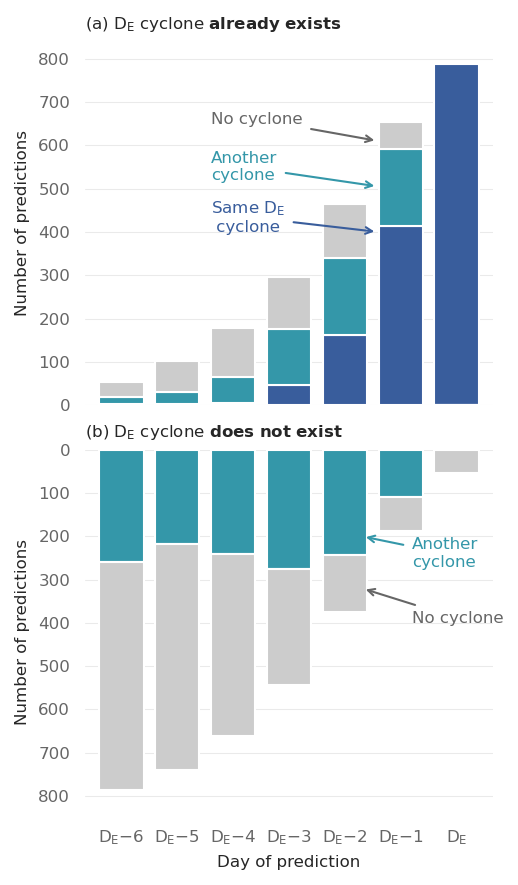

In [12]:
colors= ['#1B7F79','#8CC7C2']
colors = sns.color_palette('mako', n_colors=4)[1:3]
sns.set_style('whitegrid')
fig, axs = plt.subplots(2,1, figsize=(3.5,6), sharex=True )
df_plot = all_top_used_track.reset_index().groupby('index').sum(numeric_only=True)
df_plot2 = all_top_used_track.query("main_cyclone_D0_exists").reset_index().groupby('index').sum(numeric_only=True)[['main_cyclone_D0_is_main_cyclone_and_above_10percent','D0_cyclone_exists__but_other_cyclone_used','D0_cyclone_exists__but_no_cyclone_used',]]

df_plot3=all_top_used_track.query("main_cyclone_D0_exists == False").reset_index().groupby('index').sum(numeric_only=True)[['D0_cyclone_doesnt_exist__but_cyclones_above10percent','D0_cyclone_doesnt_exist__and_no_cyclones_above10percent',]]
df_plot2.plot.bar(stacked=True, ax=axs[0], color=colors  + [(.8,.8,.8)], edgecolor='1', width=.8)
df_plot3.plot.bar(stacked=True, ax=axs[1], color=colors[1:]  + [(.8,.8,.8)], edgecolor='1', width=.8)

for ax in axs:
    ax.grid()
    ax.grid(axis='y', linestyle='-', alpha=.4, lw=.5)
    sns.despine(ax=ax, left=True, bottom=True, right=True)
    ax.legend().remove()
    ax.tick_params(rotation=0)
    ax.set_xticks(np.arange(0,7))
    ax.set_xticklabels([r"D$_\text{E}\minus$"+str(-i) if i < 0 else r"D$_\text{E}$"  for i in range(-6,1)])
    ax.set_xlabel("Day of prediction")
    ax.set_ylim(0,840)
    ax.tick_params(left=False,labelleft=True, )
    ax.set_ylabel("Number of predictions")
axs[1].set_ylim(840,0)

axs[0].set_xlabel('')
# axs[0].text(-.5,750,"Cyclone associated with the prediction:")
axs[0].annotate(xy = (4.6,610), xytext=(1.6, 650), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[0].annotate(xy = (4.6,505), xytext=(1.6, 520), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )
axs[0].annotate(xy = (4.6,400), xytext=(1.6, 400), text='Same '+r'D$_\text{E}$'+'\n cyclone', arrowprops=dict(arrowstyle='->', color=colors[0]),color=colors[0] )

axs[1].annotate(xytext = (5.2,400), xy=(4.3, 320), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[1].annotate(xytext = (5.2,270), xy=(4.3, 200), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )

axs[0].set_title(r'(a) D$_{\text{E}}$ cyclone $\mathbf{already}$ $\mathbf{exists}$', loc='left', size=8)
axs[1].set_title(r'(b) D$_{\text{E}}$ cyclone $\mathbf{does}$ $\mathbf{not}$ $\mathbf{exist}$', loc='left', size=8)

# fig.suptitle('Cyclone associated with the predictions when:', size=9, weight='normal')
plt.tight_layout()
pos = axs[1].get_position()
axs[1].set_position([pos.x0 , pos.y0+.01, pos.width, pos.height])

plt.savefig('../paper/plots/pdf_revisions/fig07.pdf', bbox_inches='tight')


In [13]:
(df_plot2.T/df_plot2.sum(axis=1).T).T

,main_cyclone_D0_is_main_cyclone_and_above_10percent,D0_cyclone_exists__but_other_cyclone_used,D0_cyclone_exists__but_no_cyclone_used
index,,,
-6,0.037736,0.339623,0.622642
-5,0.019802,0.277228,0.702970
-4,0.033708,0.331461,0.634831
-3,0.158784,0.439189,0.402027
-2,0.349138,0.383621,0.267241
-1,0.632466,0.272588,0.094946
0,1.000000,0.000000,0.000000


## Figure 8: cyclone-centred composites

In [14]:
import numpy as np

def motion_angle_central(x, y, speed_min=None):
    """
    Compute motion angle at all points using
    central differences (interior) and forward/backward
    differences (edges).

    Parameters
    ----------
    x, y : 1D array-like
        Coordinates (x eastward, y northward)
    speed_min : float or None
        Minimum displacement threshold. Angles with
        smaller speed are set to NaN.

    Returns
    -------
    theta : ndarray
        Motion angle in radians, same length as x/y
    speed : ndarray
        Displacement magnitude used for the angle
    """
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)

    dx = np.zeros(n)
    dy = np.zeros(n)

    # Interior points: central difference
    dx[1:-1] = x[2:] - x[:-2]
    dy[1:-1] = y[2:] - y[:-2]

    # Edges: forward / backward difference
    dx[0]  = x[1] - x[0]
    dy[0]  = y[1] - y[0]
    dx[-1] = x[-1] - x[-2]
    dy[-1] = y[-1] - y[-2]

    speed = np.sqrt(dx**2 + dy**2)

    theta = np.arctan2(dy, dx)

    if speed_min is not None:
        theta = np.where(speed >= speed_min, theta, np.nan)

    return theta, speed


In [15]:
ds_features['wind_speed'] = np.hypot(ds_features.u850, ds_features.v850)
wind_speed_mean = ds_features.wind_speed.mean('time').expand_dims(var_name=['wind_speed'])
wind_speed_std = ds_features.wind_speed.std().expand_dims(var_name=['wind_speed'])
features = ds_features[['msl','u850','v850','wind_speed']].to_array('var_name')
features_mean = xr.concat([ds_features.data_mean.sel(var_name=['msl','u850','v850']), wind_speed_mean], dim='var_name')
features_std = xr.concat([ds_features.data_std.sel(var_name=['msl','u850','v850']), wind_speed_std], dim='var_name')
data_features_normed = (features -features_mean) / features_std
ds_to_shift = xr.Dataset(dict(features=features,anoms=data_features_normed))

In [16]:
import scipy
all_shifted_features = []
all_test_ = gdf_cyclones.query("is_cyclone")
for k, test_ in tqdm(top_cycs_data.query("patch_attributions>0.1").dropna().iterrows()):
    feature_date = k[0] + pd.Timedelta("1D")*k[1]
    data_features = ds_to_shift.sel(time=feature_date)
    shift_features_normed = data_features.shift(x=-int((test_.cyclone_x+2.5e6)//117000), y=-int((test_.cyclone_y+2.5e6)//117000))
    cycs_traj = all_cyclones.set_index('track_id').loc[[test_.cyclone_track_id]]
    # cycs_traj["theta"] = np.degrees(np.arctan2(cycs_traj["dy"], cycs_traj["dx"]))
    if cycs_traj.lon.size ==1:
        theta = 0
    else:
        theta,_ = motion_angle_central(cycs_traj.x, cycs_traj.y)
    cycs_traj["theta"] = np.degrees(theta)
    angle = cycs_traj.set_index('date')["theta"].loc[test_.time_of_event + pd.Timedelta('1D')*test_.timestep_past]

    for var_name in ['msl', 'u850', 'v850','wind_speed']:
        shift_features_normed['features'].loc[dict(var_name=var_name)] = scipy.ndimage.rotate(shift_features_normed['features'].loc[dict(var_name=var_name)].fillna(0),axes=(0,1), angle=-angle, reshape=False)
        shift_features_normed['anoms'].loc[dict(var_name=var_name)] = scipy.ndimage.rotate(shift_features_normed['anoms'].loc[dict(var_name=var_name)].fillna(0),axes=(0,1), angle=-angle, reshape=False)

    # rotated = scipy.ndimage.rotate((shift_features_normed.fillna(0)),axes=(0,1), angle=-angle, reshape=False)
    # rotated_features = xr.DataArray(rotated, coords = shift_features_normed.coords, dims=shift_features_normed.dims)
    all_shifted_features.append(shift_features_normed.assign_coords(cyclone_track_id = test_.cyclone_track_id))
shifted_features = xr.concat(all_shifted_features, dim='cyclone')
mean_shifted_features = shifted_features.mean('cyclone')

0it [00:00, ?it/s]

In [17]:
import scipy
all_shifted_attrs = []
all_test_ = gdf_cyclones.query("is_cyclone")
for k, test_ in tqdm(top_cycs_data.query("patch_attributions>0.1").dropna().iterrows()):
    shift_attrs = lrp_normed_vars.sel(time_of_event=test_.time_of_event, timestep_past=test_.timestep_past).shift(x=-int((test_.cyclone_x+2.5e6)//117000), y=-int((test_.cyclone_y+2.5e6)//117000))
    cycs_traj = all_cyclones.set_index('track_id').loc[[test_.cyclone_track_id]]
    # cycs_traj["theta"] = np.degrees(np.arctan2(cycs_traj["dy"], cycs_traj["dx"]))
    if cycs_traj.lon.size ==1:
        theta = 0
    else:
        theta,_ = motion_angle_central(cycs_traj.x, cycs_traj.y)
    cycs_traj["theta"] = np.degrees(theta)
    angle = cycs_traj.set_index('date')["theta"].loc[test_.time_of_event + pd.Timedelta('1D')*test_.timestep_past]
    rotated = scipy.ndimage.rotate((shift_attrs.fillna(0)),axes=(0,1), angle=-angle, reshape=False)
    rotated_attrs = xr.DataArray(rotated, coords = shift_attrs.coords, dims=shift_attrs.dims)
    all_shifted_attrs.append(rotated_attrs.assign_coords(cyclone_track_id = test_.cyclone_track_id))
shifted_attrs = xr.concat(all_shifted_attrs, dim='cyclone')
mean_shifted_attrs = shifted_attrs.mean('cyclone')

0it [00:00, ?it/s]

In [18]:
attr_per_leadtime = shifted_attrs.groupby(shifted_attrs.timestep_past).mean()

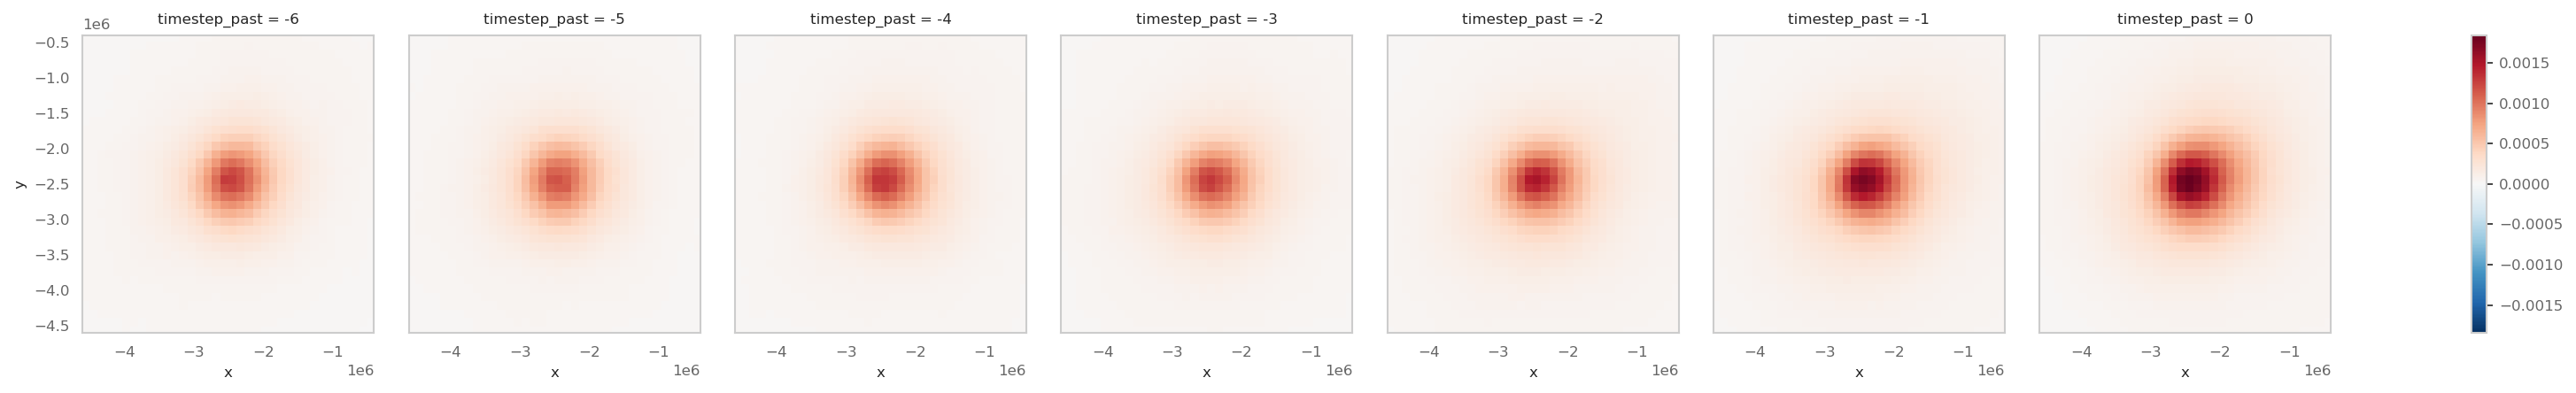

In [19]:
plot = attr_per_leadtime.isel(var_name=range(2,3)).sum('var_name').plot(col='timestep_past')
for ax in plot.axs.flat:
    ax.set(xlim=(-4.6e6,-.4e6), ylim=(-4.6e6,-.4e6))

<>:98: SyntaxWarning: invalid escape sequence '\s'
<>:98: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2581019/1378010278.py:98: SyntaxWarning: invalid escape sequence '\s'
  axs['x'].set_yticklabels([f"${i:.0f}\sigma$" for i in np.arange(-3,3.1,1)])


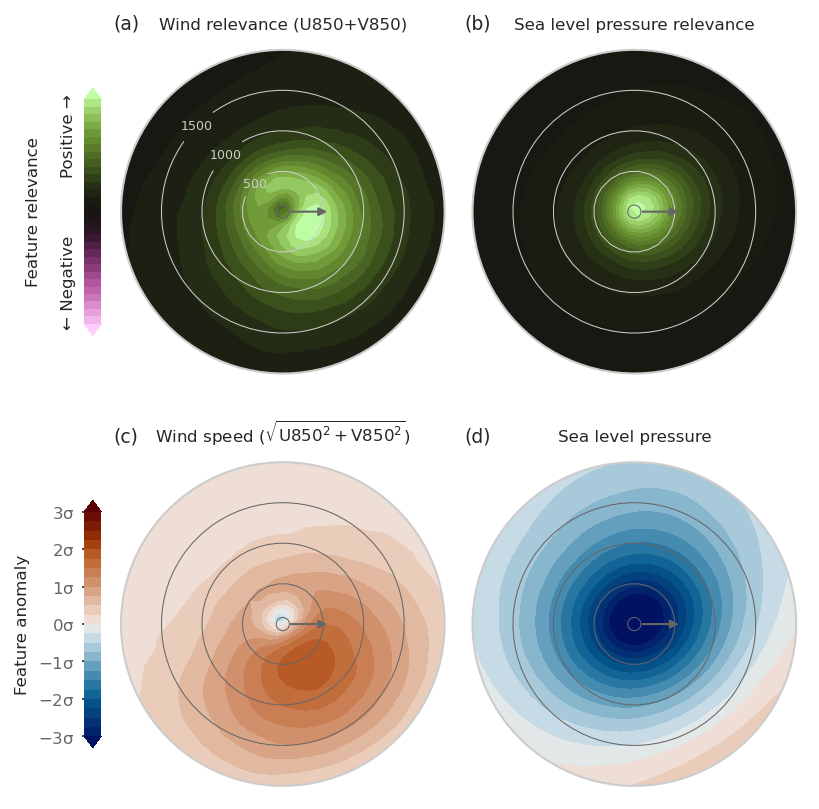

In [20]:
field_cmap =cmc.vik
relevance_cmap = cmc.vanimo
distance_from_centre = np.sqrt(((shifted_attrs.x+2.5e6)/1000)**2 + ((shifted_attrs.y+2.5e6)/1000)**2)

fig, axs = plt.subplot_mosaic(""" 
                              .CE
                              yCE
                              yCE
                              yCE
                              yCE
                              .CE
                              .AB
                              xAB
                              xAB
                              xAB
                              xAB
                              .AB
                              """,
                              per_subplot_kw=dict(ABCE=dict(projection=proj)),
                            width_ratios=[.5,10,10],
                              figsize=(6,5.8))

mean_shifted_features_norm = mean_shifted_features/np.abs(mean_shifted_features).quantile(.999,['x','y'])

plot3 = mean_shifted_attrs.isel(var_name=[0,1]).sum('var_name').plot.contourf( cmap=relevance_cmap,cbar_ax=axs['y'], ax=axs['C'], levels=np.arange(-0.0012,0.00121,0.0001), cbar_kwargs=dict(orientation='vertical',shrink=.7, aspect=15, pad=.05, ticks=[]), extend='both')
plot4 = mean_shifted_attrs.sel(var_name='msl').plot.contourf( cmap=relevance_cmap,cbar_ax=axs['y'], ax=axs['E'], levels=np.arange(-0.0015,0.00151,0.0001), cbar_kwargs=dict(orientation='vertical',shrink=.7, aspect=15, pad=.05, ticks=[]), extend='both')

plot1 = mean_shifted_features.anoms.sel(var_name='wind_speed').plot.contourf( cmap=field_cmap, ax=axs['A'], cbar_ax=axs['x'], levels=np.arange(-3.,3.01,.25), cbar_kwargs=dict(orientation='vertical',shrink=.7, aspect=15, pad=.05, ticks=[]), extend='both')
plot2 = (mean_shifted_features.anoms.sel(var_name='msl')).plot.contourf( cmap=field_cmap, ax=axs['B'], cbar_ax=axs['x'], levels=np.arange(-3,3.01,.25), cbar_kwargs=dict(orientation='vertical',shrink=.7, aspect=15, pad=.05, ticks=[]), extend='both')
# (mean_shifted_features_norm.sel(var_name='wind_speed')).plot.contour( colors='.9', ax=axs['A'], levels=np.arange(-1,1.01,.05),linestyles='-', linewidths=.5, alpha=.3)
# (mean_shifted_features_norm.sel(var_name='msl')).plot.contour( colors='.9', ax=axs['B'], levels=np.arange(-1,1.01,.05),linestyles='-', linewidths=.5, alpha=.3)


    
for k,letter in enumerate('ABCE'):
    ax = axs[letter]
    ax.set(xlim=(-4.6e6,-.4e6), ylim=(-4.6e6,-.4e6))
    color = '.4' if letter in 'AB' else '.8'
    contour = distance_from_centre.plot.contour(levels=[500, 1000,1500], colors=color, linewidths=.5, ax=ax,linestyles='-')
    if letter=='C':
        levels = [500, 1000, 1500]            # contour levels in km
        cx, cy = -2.5e6, -2.5e6                     # cyclone centre (axes in metres)
        theta = np.deg2rad(135)                     # upper-left radius
        pos = [(cx + r*1e3*np.cos(theta), cy + r*1e3*np.sin(theta)) for r in levels]

        labels = ax.clabel(contour, levels=levels, manual=pos,
                        fmt=lambda x: f"{x:.0f} km" if x == 2000 else f"{x:.0f}",
                        inline=True, inline_spacing=3, fontsize=6, rightside_up=True)
        for t in labels:
            t.set_rotation(0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')


for letter in 'ABCE':
    axs[letter].annotate("", xytext=(-2.45e6,-2.5e6), xy=(-1.9e6,-2.5e6),
            arrowprops=dict(arrowstyle="-|>",edgecolor='.4' if letter=='B' else '.4' , facecolor='.4' if letter=='B' else '.4'))
    sns.scatterplot(x=[-2.5e6],y=[-2.5e6],ax=axs[letter],marker='o', color='none',s=40, zorder=100, edgecolor='.4' if letter=='B' else '.4', linewidth=.5, legend=False)


axs['A'].set_title(r'Wind speed $(\sqrt{U850^2+V850^2})$', size=8)
axs['B'].set_title(r'Sea level pressure', size=8)
axs['A'].set_title('(c)', size=9,weight='normal', loc='left')
axs['B'].set_title('(d)', size=9,weight='normal', loc='left')

axs['C'].set_title('Wind relevance (U850+V850)', size=8)
axs['E'].set_title('Sea level pressure relevance', size=8)
axs['C'].set_title('(a)', size=9,weight='normal', loc='left')
axs['E'].set_title('(b)', size=9,weight='normal', loc='left')


axs['x'].set_yticks([])
axs['y'].set_yticks([])

axs['x'].set_ylabel('Feature anomaly')
axs['x'].yaxis.set_label_position('left')

axs['y'].set_yticks([])
axs['y'].set_ylabel('Feature relevance')
axs['y'].yaxis.set_label_position('left')
# twiny = axs['y'].twinx()
# twiny.set(ylabel='← Lesser              Higher →', yticks=[])
axs['y'].set(ylabel='Feature relevance\n\n← Negative           Positive →', yticks=[])


for cax in [axs['x'], axs['y']]:
    cax.tick_params(axis='both', which='both', length=0)  # removes tick marks
    for spine in cax.spines.values():
            spine.set_visible(False)
    
    for mappable in [plot1, plot2, plot3, plot4]:
        if hasattr(mappable, 'colorbar') and mappable.colorbar:
            mappable.colorbar.outline.set_visible(False)

axs['x'].set_yticks(np.arange(-3,3.1,1))
axs['x'].set_yticklabels([f"${i:.0f}\sigma$" for i in np.arange(-3,3.1,1)])
axs['x'].tick_params(axis='y', which='major', length=1)  # removes tick marks
axs['x'].tick_params(left=True, labelleft=True, right=False, labelright=False, )
# axs['x'].set_ylim(-3,3)
# axs['y'].set_ylim(0,0.0016)

import matplotlib.path as mpath
_theta = np.linspace(0, 2*np.pi, 100)
_cx, _cy, _r = -2.5e6, -2.5e6, 2.e6   # centre and radius matching xlim/ylim extent
_verts = np.column_stack([_cx + _r*np.cos(_theta), _cy + _r*np.sin(_theta)])
_codes = np.full(len(_theta), mpath.Path.LINETO, dtype=mpath.Path.code_type)
_codes[0] = mpath.Path.MOVETO
_circle = mpath.Path(_verts, _codes)
for letter in 'ABCE':
    axs[letter].set_boundary(_circle, transform=proj)





plt.tight_layout()
fig.subplots_adjust(wspace=0.05, hspace=0.05, left=0.18, right=0.98)
plt.savefig('../paper/plots/pdf_revisions/fig08.pdf', bbox_inches='tight')


In [21]:
# shifted_attrs

## Figure 9: cyclone strength

In [22]:
all_seen_cyclones = []

for time_of_event in tqdm(ds_attrs.time_of_event.values):
    for timestep_past in ds_attrs.timestep_past.values:
        date = time_of_event+pd.Timedelta("1D")*timestep_past
        cycs_seen_one_day = all_cyclones.set_index('date').loc[date].set_index('key')
        cycs_seen_one_day['used'] = [False for k in range(cycs_seen_one_day.index.size)]
        try:
            cycs_seen_one_day.loc[top_cycs_data.query("patch_attributions>0.1").dropna().loc[time_of_event, timestep_past].key, 'used'] = True
        except:
            pass
        all_seen_cyclones.append(cycs_seen_one_day[['msl','used']])
seen_cyclones = pd.concat(all_seen_cyclones)


  0%|          | 0/840 [00:00<?, ?it/s]

In [23]:
all_seen_cyclones = []

for time_of_event in tqdm(ds_attrs.time_of_event.values):
    for timestep_past in ds_attrs.timestep_past.values:
        date = time_of_event+pd.Timedelta("1D")*timestep_past
        cycs_seen_one_day = all_cyclones.set_index('date').loc[date].set_index('key')
        cycs_seen_one_day['used'] = [False for k in range(cycs_seen_one_day.index.size)]
        try:
            cycs_seen_one_day.loc[top_cycs_data.query("patch_attributions>0.1").dropna().loc[time_of_event, timestep_past].key, 'used'] = True
        except:
            pass
        all_seen_cyclones.append(cycs_seen_one_day[['msl','used']])
seen_cyclones = pd.concat(all_seen_cyclones)


  0%|          | 0/840 [00:00<?, ?it/s]

In [24]:
print(top_cycs_data.query("patch_attributions>0.1").dropna().cyclone_msl.quantile([.05,.5,.95])/100) 
print(seen_cyclones.msl.quantile([.05,.5,.95])/100) 


0.05    945.083626
0.50    968.713541
0.95    991.010859
Name: cyclone_msl, dtype: float64
0.05     966.000754
0.50     996.834945
0.95    1015.469922
Name: msl, dtype: float64


/tmp/ipykernel_2581019/1249798689.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_used = seen_cyclones.groupby(['used',pd.cut(seen_cyclones.msl/100, [900] + list(np.arange(930,1041,10)))]).size().unstack().T


22142

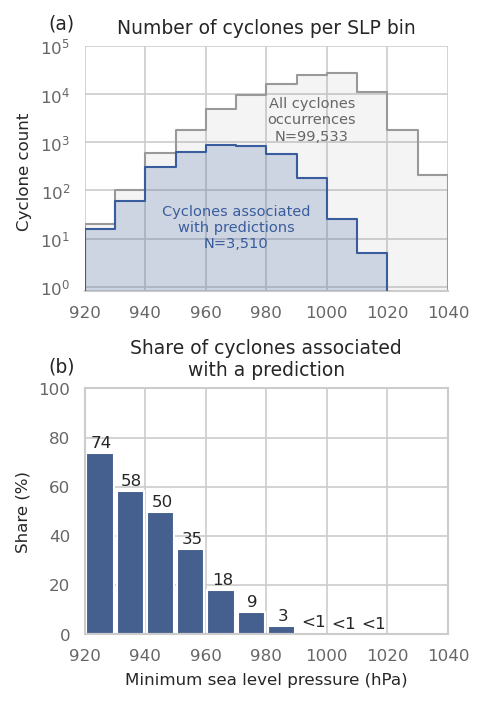

In [25]:
fig, axs = plt.subplots(2,1,figsize=(8.3/inch_to_cm,12/inch_to_cm), )#,width_ratios = [2,1.5])
color = sns.color_palette('mako', n_colors=4)[1]
sns.histplot(top_cycs_data.query("patch_attributions>0.1").dropna().cyclone_msl/100, element='step',bins=np.arange(920,1041,10), stat='count', color=color, alpha=.2, linewidth=1, label='Cyclones associated\nwith predictions', ax=axs[0], zorder=100)
sns.histplot(seen_cyclones.msl/100, element='step', bins=np.arange(920,1041,10), stat='count', color='.6', alpha=.1, linewidth=1, label='All cyclones', ax=axs[0])
sns.despine(ax=axs[0], left=True)
axs[0].tick_params()
axs[0].set_ylabel('Cyclone count ')
axs[0].set_title('Number of cyclones per SLP bin', size=9)
axs[0].set_xlabel('',)
axs[0].set_xlim(920,1040)
axs[0].set_ylim(.8,1e5)
# axs[0].text(0,1.03,'a', transform=axs[0].transAxes, va='bottom', ha='left', weight='bold')
# axs[1].text(0,1.03,'b', transform=axs[1].transAxes, va='bottom', ha='left', weight='bold')
axs[0].text(-.1,1.05,'(a)', size=9, transform=axs[0].transAxes, va='bottom', ha='left', weight='normal')


axs[1].text(-.1,1.05,'(b)', size=9, transform=axs[1].transAxes, va='bottom', ha='left', weight='normal')

axs[0].text(970,6.5,"Cyclones associated\nwith predictions\nN=3,510", color=color, ha='center', size=7)
axs[0].text(995,1.1e3,"All cyclones\noccurrences\nN=99,533", color='.4', ha='center', size=7)
# axs[0].legend(loc = (-.1,.7))

axs[0].set_yscale('log')
df_used = seen_cyclones.groupby(['used',pd.cut(seen_cyclones.msl/100, [900] + list(np.arange(930,1041,10)))]).size().unstack().T
df_used['Total'] = df_used.sum(axis=1)
ratio = df_used[True]/df_used.Total*100
ratio.index = [k.right-5 for k in ratio.index]
sns.barplot(ratio,width=.9, color=color, ax=axs[1], native_scale=True)
for k in ratio.index[:-2]:
    if k <=990:
        axs[1].text(k+.5,ratio.loc[k]+1,f"{ratio.loc[k]:.0f}", ha='center', va='bottom', size=8)
    else:
        axs[1].text(k+.5,ratio.loc[k]+1,f"<1", ha='center', va='bottom', size=8)
# ax = axs[0].twinx()
# axs[1].set_xlim(-.5,11)
# axs[1].set_xticks([k for k in range(9)])
axs[1].set_xlabel('')
axs[1].set_ylabel('Share (%)')
axs[1].set_xlim(920,1040)
axs[1].set_ylim(0,100)

axs[1].set_title('Share of cyclones associated\nwith a prediction', size=9)
axs[1].set_xlabel('Minimum sea level pressure (hPa)')

plt.tight_layout()
plt.savefig('../paper/plots/pdf_revisions/fig09.pdf', bbox_inches='tight')
seen_cyclones.index.str.split(' ', expand=True).get_level_values(1).unique().size

## Figure 10: cyclone location

In [26]:
import matplotlib.patches as mpatches
import numpy as np
from shapely.geometry import Polygon

def get_polygon(lon_min, lon_max, lat_min, lat_max,
                polygon_kwargs = dict(closed=True, facecolor='orange', alpha=0.5)):
    points_lon = list(np.linspace(lon_min, lon_max, 100)) + [lon_max for k in range(100)] + list(np.linspace(lon_max, lon_min, 100)) + [lon_min for k in range(100)]
    points_lat =  [lat_min for k in range(100)] + list(np.linspace(lat_min, lat_max, 100)) + [lat_max for k in range(100)]+ list(np.linspace(lat_max, lat_min, 100))
    vertices = list(zip(points_lon, points_lat))
    polygon_patch = mpatches.Polygon(vertices, transform=ccrs.PlateCarree(), **polygon_kwargs)
    return polygon_patch



def get_shapely_polygon(lon_min, lon_max, lat_min, lat_max,):
    points_lon = list(np.linspace(lon_min, lon_max, 100)) + [lon_max for k in range(100)] + list(np.linspace(lon_max, lon_min, 100)) + [lon_min for k in range(100)]
    points_lat =  [lat_min for k in range(100)] + list(np.linspace(lat_min, lat_max, 100)) + [lat_max for k in range(100)]+ list(np.linspace(lat_max, lat_min, 100))
    
    vertices = list(zip(points_lon, points_lat))
    polygon = Polygon(vertices, )
    return polygon

def get_shapely_polygon_from_points(p1, p2, p3, p4, n=100):
    points = []
    corners = [p1, p2, p3, p4, p1]  # close the loop
    for (x0, y0), (x1, y1) in zip(corners[:-1], corners[1:]):
        xs = np.linspace(x0, x1, n, endpoint=False)
        ys = np.linspace(y0, y1, n, endpoint=False)
        points.extend(zip(xs, ys))
    return Polygon(points)


# NAm = get_shapely_polygon(-100,-120,30,90,)
WestAtl = get_shapely_polygon(-40,-100,40,90)
EastAtl = get_shapely_polygon(-10,-40,40,90)
Tropics = get_shapely_polygon(-100,40,-10,40)


# Arctic2 = get_shapely_polygon(0,360,80,90)

Arctic1 = get_shapely_polygon(30,360-100,60,90)
# ArcticAsia = get_shapely_polygon(130,30,60,90)
Pacific1 = get_shapely_polygon(130,360-100,0,90)
# Pacific2 = get_shapely_polygon(-100,-110,0,30)

Asia = get_shapely_polygon(130,40,0,90)
# Norge = get_shapely_polygon(-10,30,30,80)
Europe = get_shapely_polygon(-10,40,40,90)


gdf_sectors = gpd.GeoDataFrame(geometry=[
                                 Europe,
                                 EastAtl,
                                 WestAtl,
                                 Pacific1,
                                 Asia,
                                 Tropics,
                                 
                                #  ArcticAsia,
                                #  Arctic1,
                                 # Norge,
                                 ], 
                        index = [
                                'Europe',
                                'East Atlantic',
                                'West Atlantic',
                                'Pacific',
                                'Asia',
                                'Tropics',
                                # 'Arctic Asia',
                                # 'Arctic',
                                # 'Norway',
                                ],         
                        crs=ccrs.PlateCarree())

palette = sns.color_palette(sns.color_palette('Greys',8)[1:6] + sns.color_palette('mako',3)[-3:])
palette

region_colors = {
    "Europe":        "#4DD5D3",
    "East Atlantic": "#34559B",
    "West Atlantic": "#171660",
    "Pacific":       "#7E7E7E",
    "Asia":          "#5A5A5A",
    "Tropics":       "#BFBFBF",
    # "Arctic":   "#D9D9D9",
    # "Arctic Pacific":"#EEEEEE",
    "All regions":   "#DC0000",
    "No cyclone": "#9A8F87"
}
gdf_sectors['color'] = pd.Series(region_colors)
gdf_sectors['marker'] = ['o','o','o','>','>','>',]
gdf_sectors['linewidth'] =[2,2,2,1,1,1]
# gdf_sectors.plot(ax=ax, transform=ccrs.PlateCarree(), legend=True, color=gdf_sectors.color)

from shapely.geometry import Point
geometry = [Point(xy) for xy in zip(gdf_cyclones.cyclone_lon, gdf_cyclones.cyclone_lat)]

# create GeoDataFrame
gdf_cyclones_center = gpd.GeoDataFrame(
    geometry=geometry,
    crs="EPSG:4326"   # WGS84 lon/lat
)
cyclones_with_sector = gpd.sjoin(
    gdf_cyclones_center.to_crs(proj),
    gdf_sectors.to_crs(proj),
    how="left",
    predicate="within"   # or "intersects" if needed
)
gdf_cyclones['cyclone_region'] = cyclones_with_sector.index_right

cyclones_with_sector_all_cyclones = gpd.sjoin(
    all_cyclones.to_crs(proj),
    gdf_sectors.to_crs(proj),
    how="left",
    predicate="within"   # or "intersects" if needed
)
cyclones_with_sector_all_cyclones
all_cyclones['cyclone_region'] = cyclones_with_sector_all_cyclones.groupby('key').index_right.first().loc[all_cyclones.key].values
# gdf_cyclones

In [ ]:
from pyproj import Proj, Transformer, CRS

all_df_dailys = []
import glob
files = glob.glob('/Data/gfi/share/Reanalyses/ERA-5/detected_features/cyclone_tracks_melbourne/*.pos.nc')
files = [f for f in files if f.endswith('.nc')]
proj_stereo = CRS(f"+proj=stere +lat_0=90 +lat_ts=70 +lon_0=0 +x_0=0 +y_0=0 +ellps=WGS84 +units=m")
transformer = Transformer.from_crs("EPSG:4326", proj_stereo, always_xy=True)
for file in tqdm(files):
    with xr.open_dataset(file) as ds:
        df_ = ds[['track_id', 'lon','lat','msl','date']].to_dataframe()
        df_['date'] = pd.to_datetime(df_.date.dt.date)
        df_daily = df_.groupby(['date','track_id']).agg({'msl':'min','lon':'mean','lat':'mean'}).reset_index()   
        x,y = transformer.transform(df_daily['lon'].values, df_daily['lat'].values)
        df_daily['x'] = x
        df_daily['y'] = y
        all_df_dailys.append(df_daily)
        del df_
daily_cycs = pd.concat(all_df_dailys)
daily_cycs = daily_cycs.loc[(daily_cycs.x > -1e7)&(daily_cycs.x < .5e7)&(daily_cycs.y > -1e7)&(daily_cycs.y < .5e7)]
daily_cycs = daily_cycs.set_index('date').sort_index()
daily_cycs['track_id']=daily_cycs['track_id'].astype(int)#.astype(float)
daily_cycs['key'] = daily_cycs.index.strftime("%Y-%m-%d") + ' '+daily_cycs.track_id.astype(str)

cyclones_gdf = gpd.GeoDataFrame(
    daily_cycs.reset_index(),
    geometry=gpd.points_from_xy(daily_cycs["x"], daily_cycs["y"]),
    crs=proj  # adjust if your cyclones are in another CRS
).set_index('date')

  0%|          | 0/552 [00:00<?, ?it/s]

In [ ]:
cyclones_gdf_with_sector = gpd.sjoin(
    cyclones_gdf.reset_index().set_index(['date','track_id']).to_crs(proj),
    gdf_sectors.to_crs(proj),
    how="left",
    predicate="within"   # or "intersects" if needed
).reset_index().set_index('date')
cyclones_gdf_with_sector['id_date'] = cyclones_gdf_with_sector.track_id.astype(str) + '_' + cyclones_gdf_with_sector.index.strftime("%Y-%m-%d")
# cyclones_gdf['cyclone_region'] = cyclones_gdf_with_sector.index_right


In [55]:
def find_top_cyc_label(df):
    out = df.query("is_cyclone & patch_attributions>0.1")
    if out.size==0:
        return np.nan
    else:
        return out.iloc[out.patch_attributions.argmax()].cyclone_track_id


top_cycs_label = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(
    find_top_cyc_label
).unstack()

/tmp/ipykernel_2581019/881059524.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_cycs_label = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(


In [ ]:
df_ = top_cycs_label.iloc[0].dropna()
def get_cyclone_region_from_id(df):
    df_ = df.dropna()
    cyclone_id_date = df_.astype(int).astype(str) + '_' + (df_.name+pd.Timedelta('1D')*df_.index).strftime("%Y-%m-%d")
    out = cyclones_gdf_with_sector.set_index('id_date').loc[cyclone_id_date.values].set_index(df_.index).index_right.rename('cyclone_region')
    out = out.reindex(range(-6, 1))
    return out
top_cycs_regions = top_cycs_label.apply(get_cyclone_region_from_id, axis=1)


In [ ]:
all_DE_tracks = []
for time_of_event in tqdm(top_cycs_label.index.values):
    DE_cyc = top_cycs_label.loc[time_of_event][0]
    DE_track = cyclones_gdf_with_sector.query("date<=@time_of_event & track_id==@DE_cyc")[['index_right']].iloc[-7:]#.plot()
    DE_track.index = (DE_track.index - pd.to_datetime(time_of_event))/pd.Timedelta(1,'D')
    DE_track.index = DE_track.index.rename('timestep_past')
    DE_track = DE_track.T 
    DE_track.index = [pd.to_datetime(time_of_event)]
    DE_track.index = DE_track.index.rename('time_of_event')
    DE_track['track_id'] = DE_cyc
    DE_track = DE_track.reset_index().set_index(['time_of_event','track_id'])
    all_DE_tracks.append(DE_track)
    # DE_trac
DE_tracks = pd.concat(all_DE_tracks).T.sort_index().T



  0%|          | 0/840 [00:00<?, ?it/s]

In [299]:
DE_track_copy = DE_tracks
DE_track_copy.index = top_cycs_regions.index  # == top_cycs_regions

DE_exists = DE_tracks.notnull()
Same_region_as_DE = (top_cycs_regions == DE_track_copy)
Same_DE = (top_cycs_label.T == top_cycs_label.T.loc[0]).T
Cyclone_when_DE_exists = (DE_exists & top_cycs_label.notnull())
Cyclone_no_DE= (~DE_exists & top_cycs_label.notnull())
No_Cyclone_when_DE_exists = (DE_exists & top_cycs_label.isnull())
No_Cyclone_no_DE = (~DE_exists & top_cycs_label.isnull())

df_de_exists = pd.DataFrame(dict(
    Same_DE = Same_DE.sum(),
    Same_region_as_DE_not_DE = (Same_region_as_DE & ~Same_DE).sum(),
    Cyclone_different_region = (Cyclone_when_DE_exists & ~Same_region_as_DE).sum(),
    No_cyclone = No_Cyclone_when_DE_exists.sum()))

df_de_doesnt_exists = pd.DataFrame(dict(
    Cyclone_no_DE = Cyclone_no_DE.sum(),
    No_Cyclone_no_DE = No_Cyclone_no_DE.sum(),
    ))

/tmp/ipykernel_2581019/456414702.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()
/tmp/ipykernel_2581019/456414702.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()


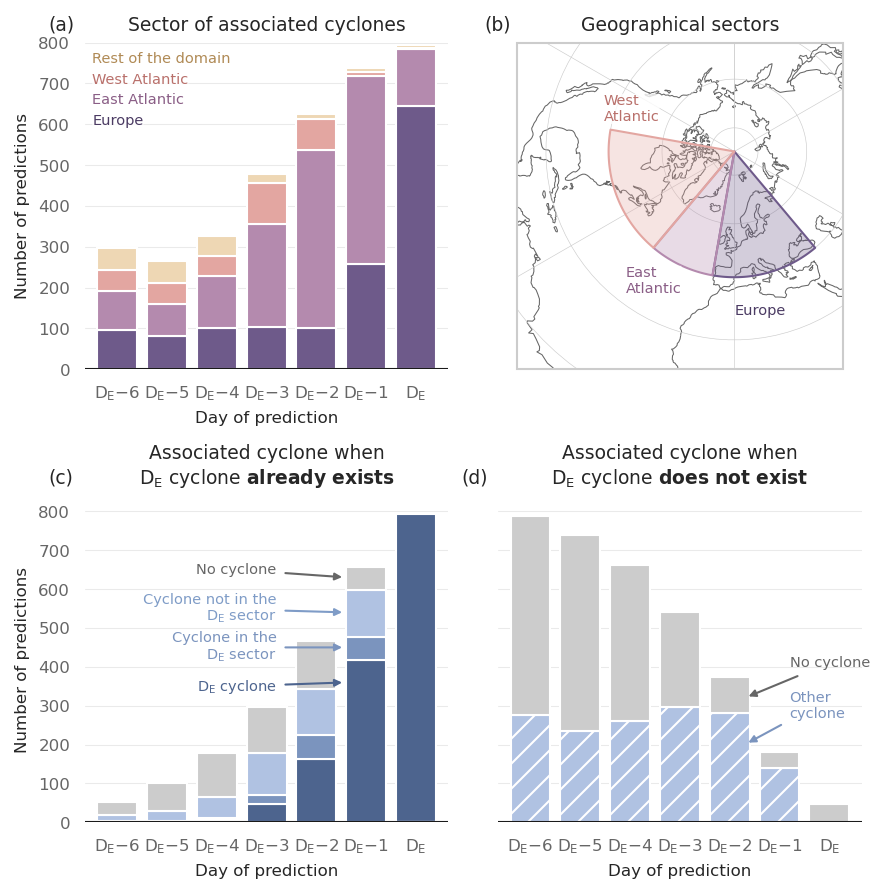

In [421]:
fig, axs = plt.subplot_mosaic([['B','A'],
                               ['C','D']], figsize=(6,6), per_subplot_kw=dict(A=dict(projection=proj)), width_ratios=[1,1])

df_sectors = top_cycs_regions.replace({'Tropics': 'Other', 'Pacific': 'Other', 'Asia': 'Other'}).stack().rename('sector').reset_index().groupby(['timestep_past','sector']).size().unstack()

sector_colors = {
    'Europe':             '#6E5A8A',   # muted plum
    'East Atlantic':      '#B48AAE',   # dusty mauve
    'West Atlantic':      '#E3A6A1',   # dusty rose
    'Rest of the domain': '#EED7B4',   # pale sand
}
# Map
colors_regions=sns.color_palette(sector_colors.values())
colors_regions_text = [ '#4B3B63', '#8A5E86','#B9706B', '#B08A55']
box_properties = dict(
    boxstyle='round,pad=0', # Box shape (e.g., square, round) and padding
    facecolor='1',        # Background color inside the box
    edgecolor='none',       # Border color
    alpha=0.8            # Transparency level (0 = transparent, 1 = opaque)
)
axs['A'].coastlines(color='.4', lw=.5)
gl = axs['A'].gridlines(lw=.3)
gdf_sectors.loc[ ['Europe','East Atlantic','West Atlantic']].plot(ax=axs['A'], transform=ccrs.PlateCarree(), legend=True,color=colors_regions,  alpha=.3, zorder=100)
gdf_sectors.loc[ ['Europe','East Atlantic','West Atlantic']].plot(ax=axs['A'], transform=ccrs.PlateCarree(), legend=True, color='none', zorder=100, edgecolor=colors_regions, alpha=1)

axs['A'].annotate(xy=(0e6,-7.5e6), text='Europe', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[0], bbox=box_properties)
axs['A'].annotate(xy=(-5e6,-6.5e6), text='East\nAtlantic', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[1], bbox=box_properties)
axs['A'].annotate(xy=(-6e6,1.4e6), text='West\nAtlantic', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[2], bbox=box_properties)
axs['A'].set_extent((-1e7, 5e6, -1e7, 5e6), crs=proj)
axs['A'].set_title('')


# Count per sector
df_sectors[[ 'Other','West Atlantic', 'East Atlantic', 'Europe'][::-1]].plot.bar(stacked=True,ax=axs['B'],
                                                    color=colors_regions+['.8','.8','.8'],legend=False,  edgecolor='1', width=.8)


axs['A'].set_title('Geographical sectors', size=9)
axs['B'].set_title('Sector of associated cyclones', size=9)




for k,ax in enumerate([axs['B'], axs['C'], axs['D']]):
    ax.grid()
    ax.grid(axis='y', linestyle='-', alpha=.4, lw=.5)
    sns.despine(ax=ax, left=True, bottom=True, right=True)
    ax.legend().remove()
    ax.tick_params(rotation=0)
    ax.set_xticks(np.arange(0,7))
    ax.set_xticklabels([r"D$_{\text{E}}\minus$"+str(-i) if i < 0 else r"D$_{\text{E}}$"  for i in range(-6,1)])
    ax.set_xlabel("Day of prediction")
    ax.set_ylim(0,800)
    ax.tick_params(left=False,labelleft=True, )

    ax.yaxis.set_minor_locator(plt.MultipleLocator(100))
    ax.grid(which='minor', axis='y', linestyle='-', alpha=.2, lw=.5)
    
    ax.axhline(0, color='.1')
    ax.tick_params(axis='y', which='minor', labelleft=True)

axs['A'].text(-.1, 1.04, f'(b)', weight='normal', transform=axs['A'].transAxes, size=9)
axs['B'].text(-.1, 1.04, f'(a)', weight='normal', transform=axs['B'].transAxes, size=9)
axs['C'].text(-.1, 1.04, f'(c)', weight='normal', transform=axs['C'].transAxes, size=9)
axs['D'].text(-.1, 1.04, f'(d)', weight='normal', transform=axs['D'].transAxes, size=9)
axs['B'].set_ylim(0,800)

axs['B'].set_ylabel('Number of predictions')
axs['B'].annotate(xy=(-.5,750), text='Rest of the domain', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[3], bbox=box_properties)
axs['B'].annotate(xy=(-.5,700), text='West Atlantic', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[2], bbox=box_properties)
axs['B'].annotate(xy=(-.5,650), text='East Atlantic', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[1], bbox=box_properties)
axs['B'].annotate(xy=(-.5,600), text='Europe', transform=axs['A'].transAxes, fontsize=7, zorder=1000, color=colors_regions_text[0], bbox=box_properties)






ramp = sns.cubehelix_palette(n_colors=4, start=2.8, rot=0, dark=0.2, light=0.75, reverse=True)[1:]
colors_cyclone_cat = ramp + ['.8']


df_de_exists.plot.bar(stacked=True, ax=axs['C'], color=colors_cyclone_cat  + [(.8,.8,.8)], edgecolor='1', width=.8)
df_de_doesnt_exists.plot.bar(stacked=True, ax=axs['D'], color=colors_cyclone_cat[2:]  + [(.8,.8,.8)], edgecolor='1', width=.8,
                                )
for bar in axs['D'].containers[0]:      # first series (first column of the DataFrame)
    bar.set_hatch('//')

for ax in [axs['C'], axs['D']]:
    ax.grid()
    ax.grid(axis='y', linestyle='-', alpha=.4, lw=.5)
    sns.despine(ax=ax, left=True, bottom=True, right=True)
    ax.legend().remove()
    ax.tick_params(rotation=0)
    ax.set_xticks(np.arange(0,7))
    ax.set_xticklabels([r"D$_\text{E}\minus$"+str(-i) if i < 0 else r"D$_\text{E}$"  for i in range(-6,1)])
    ax.set_xlabel("Day of prediction")
    ax.set_ylim(0,840)
    ax.tick_params(left=False,labelleft=True, )
    ax.set_ylabel("Number of predictions")
# axs['D'].set_ylim(840,0)

# axs['C'].set_xlabel('')
# axs['C'].text(-.5,750,"Cyclone associated with the prediction:")
axs['C'].annotate(xy = (4.6,630), xytext=(3.2, 650), text='No cyclone', arrowprops=dict(arrowstyle='-|>', color='.4'),color='.4' , ha='right',va='center', size=7)
axs['C'].annotate(xy = (4.6,540), xytext=(3.2, 550), text='Cyclone not in the\n'+r'D$_\text{E}$ sector', arrowprops=dict(arrowstyle='-|>', color="#7F9CC7"),color="#7F9CC7" , ha='right',va='center', size=7)
axs['C'].annotate(xy = (4.6,450), xytext=(3.2, 450), text='Cyclone in the\n'+r'D$_\text{E}$ sector', arrowprops=dict(arrowstyle='-|>', color=colors_cyclone_cat[1]),color=colors_cyclone_cat[1] , ha='right',va='center', size=7)
axs['C'].annotate(xy = (4.6,360), xytext=(3.2, 350), text=r'D$_\text{E}$'+' cyclone', arrowprops=dict(arrowstyle='-|>', color=colors_cyclone_cat[0]),color=colors_cyclone_cat[0] , ha='right',va='center', size=7)

axs['D'].annotate(xytext = (5.2,400), xy=(4.3, 320), text='No cyclone', arrowprops=dict(arrowstyle='-|>', color='.4'),color='.4' , size=7)
axs['D'].annotate(xytext = (5.2,270), xy=(4.3, 200), text='Other\ncyclone', arrowprops=dict(arrowstyle='-|>', color=colors_cyclone_cat[1]),color=colors_cyclone_cat[1] , size=7)

axs['C'].set_title('Associated cyclone when\n'+r'D$_{\text{E}}$ cyclone $\mathbf{already}$ $\mathbf{exists}$', loc='center', size=9)
axs['D'].set_title('Associated cyclone when\n'+r'D$_{\text{E}}$ cyclone $\mathbf{does}$ $\mathbf{not}$ $\mathbf{exist}$', loc='center', size=9)

axs['D'].tick_params(labelleft=False)
axs['D'].set_ylabel('')




plt.tight_layout()
plt.savefig('../paper/plots/pdf_revisions/fig10.pdf', bbox_inches='tight')

